# Linear PDE Problem Set Solutions (`problem_set_III.pdf`)

**References:** `Notes/problem_set_III.pdf` (Q2, Q3, Q4, Q5, Q6), `Notes/lec_pde.pdf`, `Notes/Tutorial_03_11_26.pptx`, `Notes/Quiz2/01..05`

Grouped by question type:
1. **Type 1:** Heterogeneous & 2D Diffusion (`problem_set_III.pdf` Q2, Q3)
2. **Type 2:** Implicit Stability & Fourier Mode Decay (`problem_set_III.pdf` Q5, Q6)
3. **Type 3:** 2nd-Order Wave Equation (`problem_set_III.pdf` Q4)

---
## Type 1: Heterogeneous & 2D Diffusion (`problem_set_III.pdf` Q2, Q3)

### Q2: Heterogeneous Diffusion $\frac{\partial \rho}{\partial t} = \frac{\partial}{\partial x}\left(D(x)\frac{\partial \rho}{\partial x}\right)$
- **(i) Steady State ($\frac{\partial \rho}{\partial t} = 0$):**
  $D(x)\frac{\partial \rho}{\partial x} = \text{const} = -J$. Under periodic boundary conditions, integrating over one period requires zero steady flux ($J = 0$), so $\rho(x) = \text{constant}$ (uniform distribution equal to initial average concentration).
- **(ii) Numerical check with periodic BC and $D(x) = \cos\left(\frac{\pi x}{2L}\right)$:**

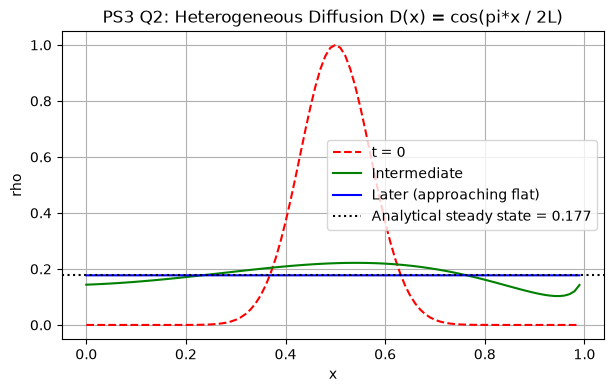

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# PS3 Q2: Heterogeneous diffusion with D(x) = cos(pi*x / (2*L)) and periodic BC
N = 100
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
dt = 0.00002

D_x = np.cos(np.pi * x / (2 * L))
D_half = 0.5 * (D_x + np.roll(D_x, -1))

assert np.max(D_x) * dt / (dx**2) <= 0.5

rho = np.exp(-100 * (x - 0.5)**2)
rho_0 = rho.copy()
steady_val = np.mean(rho_0)

for step in range(4000):
    flux = -D_half * (np.roll(rho, -1) - rho) / dx
    rho = rho - (dt / dx) * (flux - np.roll(flux, 1))
rho_mid = rho.copy()

for step in range(26000):
    flux = -D_half * (np.roll(rho, -1) - rho) / dx
    rho = rho - (dt / dx) * (flux - np.roll(flux, 1))

plt.figure(figsize=(7, 4))
plt.plot(x, rho_0, 'r--', label='t = 0')
plt.plot(x, rho_mid, 'g-', label='Intermediate')
plt.plot(x, rho, 'b-', label='Later (approaching flat)')
plt.axhline(steady_val, color='k', linestyle=':', label=f'Analytical steady state = {steady_val:.3f}')
plt.xlabel('x'); plt.ylabel('rho')
plt.title('PS3 Q2: Heterogeneous Diffusion D(x) = cos(pi*x / 2L)')
plt.legend(); plt.grid(True)
plt.show()

### Q3: 2D Diffusion Equation $\frac{\partial \rho}{\partial t} = D\left(\frac{\partial^2 \rho}{\partial x^2} + \frac{\partial^2 \rho}{\partial y^2}\right)$
- **Stability Proof Outline:** Substitute Fourier mode $\rho_{i,j}^n = T^n e^{i(k_x i + k_y j)\delta}$ into FTCS:
  $$\frac{T^{n+1}}{T^n} = 1 - 2C\big[(1 - \cos(k_x\delta)) + (1 - \cos(k_y\delta))\big] = 1 - 4C\left(\sin^2\frac{k_x\delta}{2} + \sin^2\frac{k_y\delta}{2}\right)$$
  Since $\sin^2(\cdot) \le 1$, the worst case has sum $= 2$, giving $1 - 8C \ge -1 \implies C = \frac{D\Delta t}{\delta^2} \le \frac{1}{4}$ (and $\le \frac{1}{2d}$ in $d$ dimensions).

2D Courant C = 0.20 < 0.25


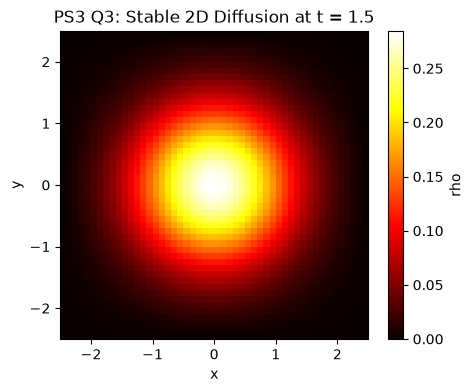

In [2]:
# PS3 Q3: Numerical verification at C = 0.20 < 0.25 with Gaussian initial condition
Nx, Ny = 50, 50
delta = 0.1
D = 0.2
dt = 0.01
C = D * dt / (delta**2)
print(f'2D Courant C = {C:.2f} < 0.25')

x_g = np.linspace(-2.5, 2.5, Nx)
y_g = np.linspace(-2.5, 2.5, Ny)
X, Y = np.meshgrid(x_g, y_g)
rho_2d = np.exp(-(X**2 + Y**2) / 0.5)

for step in range(150):
    rho_2d[1:-1, 1:-1] += C * (
        rho_2d[2:, 1:-1] + rho_2d[:-2, 1:-1] +
        rho_2d[1:-1, 2:] + rho_2d[1:-1, :-2] - 4 * rho_2d[1:-1, 1:-1]
    )

plt.figure(figsize=(5, 4))
plt.imshow(rho_2d, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot')
plt.colorbar(label='rho')
plt.title('PS3 Q3: Stable 2D Diffusion at t = 1.5')
plt.xlabel('x'); plt.ylabel('y')
plt.show()

---
## Type 2: Implicit Stability & Fourier Mode Decay (`problem_set_III.pdf` Q5, Q6)

### Q5: Explicit FTCS vs Implicit BTCS when $C > 0.5$
- Implicit amplification factor: $G(k) = \frac{1}{1 + 4C\sin^2(k\Delta x/2)} \in (0, 1]$ for all $D, \Delta t, \Delta x > 0$ (unconditionally stable).

Using C = 0.60 (> 0.5 explicit limit)


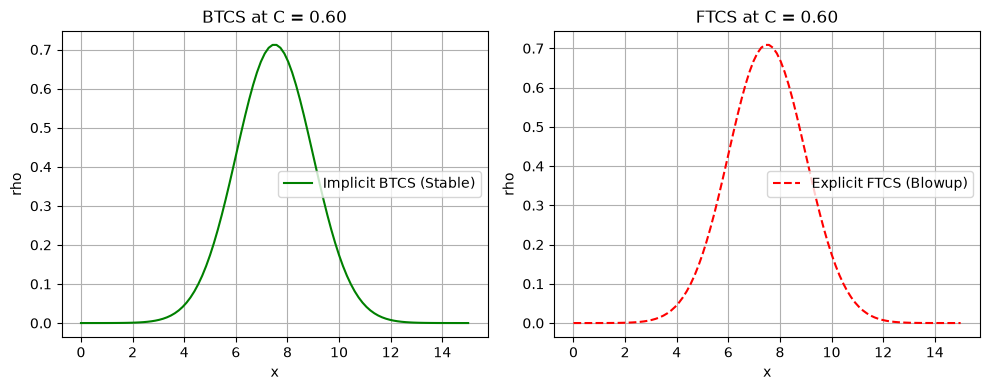

In [3]:
import scipy.linalg as la

# PS3 Q5: Compare FTCS and BTCS at C = 0.60 > 0.5
N = 100
dx = 0.15
L = N * dx
D = 0.05
dt = 0.27
C = D * dt / (dx**2)   # C = 0.60 > 0.5
print(f'Using C = {C:.2f} (> 0.5 explicit limit)')

x = np.linspace(0, L, N)
rho_init = np.exp(-((x - L/2) / 1.5)**2)
rho_ftcs = rho_init.copy()
rho_btcs = rho_init.copy()

A = np.diag((1 + 2*C)*np.ones(N)) + np.diag(-C*np.ones(N-1), -1) + np.diag(-C*np.ones(N-1), 1)
A[0, :] = 0; A[0, 0] = 1
A[-1, :] = 0; A[-1, -1] = 1

for step in range(40):
    rho_new = rho_ftcs.copy()
    rho_new[1:-1] = rho_ftcs[1:-1] + C * (rho_ftcs[2:] + rho_ftcs[:-2] - 2*rho_ftcs[1:-1])
    rho_new[0] = 0; rho_new[-1] = 0
    rho_ftcs = rho_new

    rhs = rho_btcs.copy(); rhs[0] = 0; rhs[-1] = 0
    rho_btcs = la.solve(A, rhs)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, rho_btcs, 'g-', label='Implicit BTCS (Stable)')
plt.title(f'BTCS at C = {C:.2f}'); plt.xlabel('x'); plt.ylabel('rho'); plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x, rho_ftcs, 'r--', label='Explicit FTCS (Blowup)')
plt.title(f'FTCS at C = {C:.2f}'); plt.xlabel('x'); plt.ylabel('rho'); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

### Q6: Fourier Mode Equilibration Speed ($k = 2\pi/L$ vs $k = 16\pi/L$)
- Profile: $\rho(x, t) = 1 + e^{-Dk^2 t}\sin(kx)$.
- Since decay time $\tau_k = \frac{1}{Dk^2}$, increasing $k$ by $8\times$ (from $\frac{2\pi}{L}$ to $\frac{16\pi}{L}$) makes the decay **$8^2 = 64\times$ faster** (sharper gradients produce larger flux $J = -D\frac{\partial \rho}{\partial x}$).

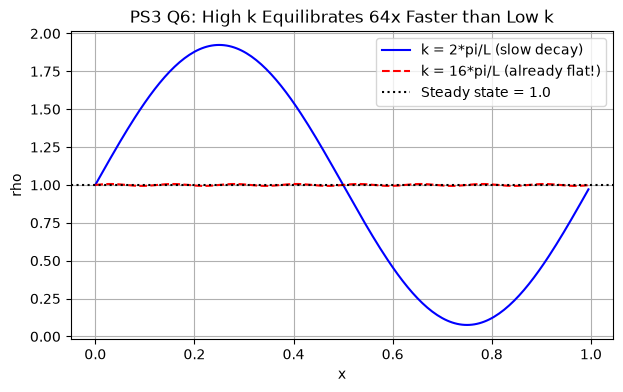

In [4]:
# PS3 Q6: Compare k_low = 2*pi/L and k_high = 16*pi/L with periodic BC
N = 200
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
D = 0.01
dt = 0.0005
C = D * dt / (dx**2)
assert C <= 0.5

k_low = 2 * np.pi / L
k_high = 16 * np.pi / L

rho_low = 1.0 + np.sin(k_low * x)
rho_high = 1.0 + np.sin(k_high * x)

for step in range(400):   # t = 0.2
    rho_low = rho_low + C * (np.roll(rho_low, -1) + np.roll(rho_low, 1) - 2*rho_low)
    rho_high = rho_high + C * (np.roll(rho_high, -1) + np.roll(rho_high, 1) - 2*rho_high)

plt.figure(figsize=(7, 4))
plt.plot(x, rho_low, 'b-', label='k = 2*pi/L (slow decay)')
plt.plot(x, rho_high, 'r--', label='k = 16*pi/L (already flat!)')
plt.axhline(1.0, color='k', linestyle=':', label='Steady state = 1.0')
plt.xlabel('x'); plt.ylabel('rho')
plt.title('PS3 Q6: High k Equilibrates 64x Faster than Low k')
plt.legend(); plt.grid(True)
plt.show()

---
## Type 3: Second-Order Wave Equation (`problem_set_III.pdf` Q4)
Parameters: $c = 100,\; \Delta t = 10^{-4},\; \Delta x = 10^{-2},\; k = \frac{c\Delta t}{\Delta x} = 1,\; N = 100,\; L = N\Delta x = 1.0$, with $\psi(0) = \psi(L) = 0$.

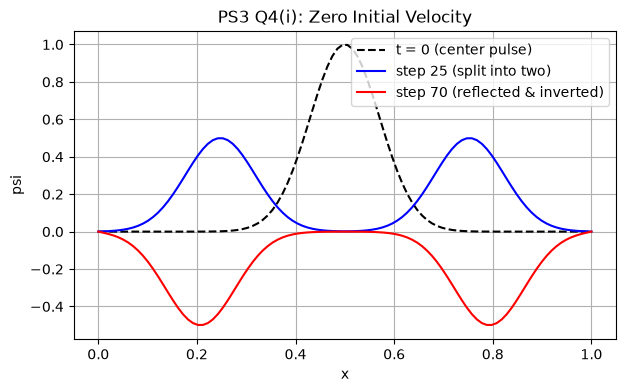

In [5]:
# PS3 Q4 (i): Zero initial velocity -> pulse splits symmetrically into left and right halves
N = 100
c = 100.0
dt = 1e-4
dx = 1e-2
L = N * dx
k = c * dt / dx   # k = 1.0
x = np.linspace(0, L, N)

psi_0 = np.exp(-100 * (x - L/2)**2)
psi_1 = np.zeros(N)
for i in range(1, N - 1):
    psi_1[i] = (k**2 / 2)*(psi_0[i+1] + psi_0[i-1]) + (1 - k**2)*psi_0[i]   # v(x) = 0

psi_prev = psi_0.copy()
psi_curr = psi_1.copy()
snaps = [psi_prev.copy()]

for step in range(2, 80):
    psi_next = np.zeros(N)
    for i in range(1, N - 1):
        psi_next[i] = (k**2)*(psi_curr[i+1] + psi_curr[i-1]) + 2*(1 - k**2)*psi_curr[i] - psi_prev[i]
    psi_prev = psi_curr.copy()
    psi_curr = psi_next.copy()
    if step in [25, 70]:
        snaps.append(psi_curr.copy())

plt.figure(figsize=(7, 4))
plt.plot(x, snaps[0], 'k--', label='t = 0 (center pulse)')
plt.plot(x, snaps[1], 'b-', label='step 25 (split into two)')
plt.plot(x, snaps[2], 'r-', label='step 70 (reflected & inverted)')
plt.xlabel('x'); plt.ylabel('psi'); plt.title('PS3 Q4(i): Zero Initial Velocity')
plt.legend(); plt.grid(True); plt.show()

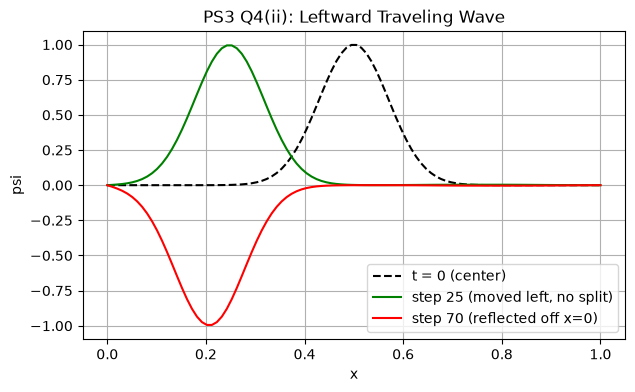

In [6]:
# PS3 Q4 (ii): Leftward traveling wave -> moves purely left without splitting
psi_l0 = np.exp(-100 * (x - L/2)**2)
v_left = -200.0 * c * (x - L/2) * np.exp(-100 * (x - L/2)**2)

psi_l1 = np.zeros(N)
for i in range(1, N - 1):
    psi_l1[i] = (k**2 / 2)*(psi_l0[i+1] + psi_l0[i-1]) + (1 - k**2)*psi_l0[i] + dt * v_left[i]

psi_prev_l = psi_l0.copy()
psi_curr_l = psi_l1.copy()
snaps_l = [psi_prev_l.copy()]

for step in range(2, 80):
    psi_next_l = np.zeros(N)
    for i in range(1, N - 1):
        psi_next_l[i] = (k**2)*(psi_curr_l[i+1] + psi_curr_l[i-1]) + 2*(1 - k**2)*psi_curr_l[i] - psi_prev_l[i]
    psi_prev_l = psi_curr_l.copy()
    psi_curr_l = psi_next_l.copy()
    if step in [25, 70]:
        snaps_l.append(psi_curr_l.copy())

plt.figure(figsize=(7, 4))
plt.plot(x, snaps_l[0], 'k--', label='t = 0 (center)')
plt.plot(x, snaps_l[1], 'g-', label='step 25 (moved left, no split)')
plt.plot(x, snaps_l[2], 'r-', label='step 70 (reflected off x=0)')
plt.xlabel('x'); plt.ylabel('psi'); plt.title('PS3 Q4(ii): Leftward Traveling Wave')
plt.legend(); plt.grid(True); plt.show()